# Toy Store Chain: Sales and Inventory Analysis

A chain of 50 toy stores (Maven Toys, Mexico) shared 21 months of sales (Jan 2022 to Sep 2023) and a stock snapshot. I used **SQL** for the analysis and **Python (pandas)** to clean and load the data and draw the charts.

**Business questions**
1. How are sales and profit growing?
2. Which categories and products actually make the profit?
3. Which store types and stores perform best and worst?
4. How much money is tied up in stock, and where are we losing sales because items are out of stock?

**Data:** 4 related tables. `sales` (829,262 rows), `products` (35), `stores` (50), `inventory` (1,593). Source: Maven Analytics free data playground (public domain). Prices are in dollars.

## 1. Load and check the data (Python)

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

sales = pd.read_csv("sales.csv.gz")
products = pd.read_csv("products.csv")
stores = pd.read_csv("stores.csv")
inventory = pd.read_csv("inventory.csv")

for name, table in [("sales", sales), ("products", products), ("stores", stores), ("inventory", inventory)]:
    print(name, table.shape)

sales (829262, 5)
products (35, 5)
stores (50, 5)
inventory (1593, 3)


In [2]:
products.head()

,Product_ID,Product_Name,Product_Category,Product_Cost,Product_Price
0,1,Action Figure,Toys,$9.99,$15.99
1,2,Animal Figures,Toys,$9.99,$12.99
2,3,Barrel O' Slime,Art & Crafts,$1.99,$3.99
3,4,Chutes & Ladders,Games,$9.99,$12.99
4,5,Classic Dominoes,Games,$7.99,$9.99


Prices are stored as text like `$15.99 `, so I remove the `$` and spaces and convert them to numbers.

In [3]:
for col in ["Product_Cost", "Product_Price"]:
    products[col] = products[col].str.replace("$", "", regex=False).str.strip().astype(float)

products[["Product_Name", "Product_Cost", "Product_Price"]].head()

,Product_Name,Product_Cost,Product_Price
0,Action Figure,9.99,15.99
1,Animal Figures,9.99,12.99
2,Barrel O' Slime,1.99,3.99
3,Chutes & Ladders,9.99,12.99
4,Classic Dominoes,7.99,9.99


Quality checks: missing values, duplicate IDs, and whether every sale points to a real product and store.

In [4]:
print("missing values in sales:", sales.isnull().sum().sum())
print("duplicate Sale_IDs:", sales["Sale_ID"].duplicated().sum())
print("sales with unknown product:", (~sales["Product_ID"].isin(products["Product_ID"])).sum())
print("sales with unknown store:", (~sales["Store_ID"].isin(stores["Store_ID"])).sum())
print("date range:", sales["Date"].min(), "to", sales["Date"].max())
print("negative stock rows:", (inventory["Stock_On_Hand"] < 0).sum())

missing values in sales: 0
duplicate Sale_IDs: 0
sales with unknown product: 0
sales with unknown store: 0


date range: 2022-01-01 to 2023-09-30
negative stock rows: 0


The data is clean. I add a `Month` column (like `2023-07`) to make monthly grouping easy, then load all 4 tables into a SQL database.

In [5]:
sales["Month"] = sales["Date"].str[:7]

conn = sqlite3.connect(":memory:")
sales.to_sql("sales", conn, index=False)
products.to_sql("products", conn, index=False)
stores.to_sql("stores", conn, index=False)
inventory.to_sql("inventory", conn, index=False)

def run(query):
    return pd.read_sql(query, conn)

## 2. Analysis with SQL
All queries are also saved in `queries.sql`.

### 1. Overall KPIs
Over 21 months the chain sold about 1.09 million units. Revenue and profit are calculated by joining each sale to the product price and cost.

In [6]:
run("""
SELECT COUNT(*)                                              AS sale_lines,
       SUM(s.Units)                                          AS units_sold,
       ROUND(SUM(s.Units * p.Product_Price))                 AS revenue,
       ROUND(SUM(s.Units * (p.Product_Price - p.Product_Cost))) AS profit,
       ROUND(100.0 * SUM(s.Units * (p.Product_Price - p.Product_Cost))
             / SUM(s.Units * p.Product_Price), 1)            AS margin_pct
FROM sales s
JOIN products p ON s.Product_ID = p.Product_ID;
""")

,sale_lines,units_sold,revenue,profit,margin_pct
0,829262,1090565,14444572.0,4014029.0,27.8


### 2. Same month, 2022 vs 2023 (self-join on a CTE)
Every month of 2023 sold more than the same month of 2022. Comparing the same month avoids mixing growth with seasonality.

In [7]:
yoy = run("""
WITH monthly AS (
    SELECT SUBSTR(s.Month, 1, 4)              AS yr,
           SUBSTR(s.Month, 6, 2)              AS mon,
           SUM(s.Units * p.Product_Price)     AS revenue
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    GROUP BY s.Month
)
SELECT a.mon                                             AS month,
       ROUND(a.revenue)                                  AS revenue_2022,
       ROUND(b.revenue)                                  AS revenue_2023,
       ROUND(100.0 * (b.revenue - a.revenue) / a.revenue, 1) AS growth_pct
FROM monthly a
JOIN monthly b ON a.mon = b.mon AND a.yr = '2022' AND b.yr = '2023'
ORDER BY a.mon;
""")
yoy

,month,revenue_2022,revenue_2023,growth_pct
0,01,542555.0,747196.0,37.7
1,02,541352.0,722632.0,33.5
2,03,589485.0,883516.0,49.9
3,04,681073.0,827691.0,21.5
4,05,672370.0,825319.0,22.7
5,06,661980.0,808299.0,22.1
6,07,556034.0,828349.0,49.0
7,08,489423.0,660877.0,35.0
8,09,585844.0,658194.0,12.3


### 3. Month-on-month change (LAG)
LAG gives the previous month's revenue on the same row, so the change can be calculated in one query.

In [8]:
monthly = run("""
WITH monthly AS (
    SELECT s.Month,
           SUM(s.Units * p.Product_Price) AS revenue
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    GROUP BY s.Month
)
SELECT Month,
       ROUND(revenue) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY Month))
             / LAG(revenue) OVER (ORDER BY Month), 1) AS mom_change_pct
FROM monthly
ORDER BY Month;
""")
monthly

,Month,revenue,mom_change_pct
0,2022-01,542555.0,NaN
1,2022-02,541352.0,-0.2
2,2022-03,589485.0,8.9
3,2022-04,681073.0,15.5
4,2022-05,672370.0,-1.3
5,2022-06,661980.0,-1.5
6,2022-07,556034.0,-16.0
7,2022-08,489423.0,-12.0
8,2022-09,585844.0,19.7
9,2022-10,623874.0,6.5


### 4. Revenue vs profit by category (share of total with a subquery)
Toys bring the most revenue, but Electronics has by far the best margin and almost the same profit as Toys.

In [9]:
categories = run("""
WITH category_totals AS (
    SELECT p.Product_Category                                    AS category,
           SUM(s.Units * p.Product_Price)                        AS revenue,
           SUM(s.Units * (p.Product_Price - p.Product_Cost))     AS profit
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    GROUP BY p.Product_Category
)
SELECT category,
       ROUND(revenue) AS revenue,
       ROUND(profit)  AS profit,
       ROUND(100.0 * revenue / (SELECT SUM(revenue) FROM category_totals), 1) AS revenue_share_pct,
       ROUND(100.0 * profit  / (SELECT SUM(profit)  FROM category_totals), 1) AS profit_share_pct,
       ROUND(100.0 * profit / revenue, 1)                                     AS margin_pct
FROM category_totals
ORDER BY profit DESC;
""")
categories

,category,revenue,profit,revenue_share_pct,profit_share_pct,margin_pct
0,Toys,5093241.0,1079527.0,35.3,26.9,21.2
1,Electronics,2246771.0,1001437.0,15.6,24.9,44.6
2,Art & Crafts,2705364.0,753354.0,18.7,18.8,27.8
3,Games,2226836.0,673993.0,15.4,16.8,30.3
4,Sports & Outdoors,2172360.0,505718.0,15.0,12.6,23.3


### 5. Top 3 products in each category (ROW_NUMBER)
One product, Colorbuds, earns about a fifth of the whole company's profit. That is a big dependency on a single item.

In [10]:
run("""
WITH product_profit AS (
    SELECT p.Product_Category AS category,
           p.Product_Name     AS product,
           ROUND(SUM(s.Units * (p.Product_Price - p.Product_Cost))) AS profit
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    GROUP BY p.Product_Category, p.Product_Name
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY category ORDER BY profit DESC) AS rank_in_category,
           ROUND(100.0 * profit / (SELECT SUM(profit) FROM product_profit), 1) AS share_of_total_profit_pct
    FROM product_profit
)
SELECT category, rank_in_category, product, profit, share_of_total_profit_pct
FROM ranked
WHERE rank_in_category <= 3
ORDER BY category, rank_in_category;
""")

,category,rank_in_category,product,profit,share_of_total_profit_pct
0,Art & Crafts,1,Barrel O' Slime,183326.0,4.6
1,Art & Crafts,2,Kids Makeup Kit,146598.0,3.7
2,Art & Crafts,3,Etch A Sketch,121680.0,3.0
3,Electronics,1,Colorbuds,834944.0,20.8
4,Electronics,2,Gamer Headphones,107748.0,2.7
5,Electronics,3,Toy Robot,58745.0,1.5
6,Games,1,Deck Of Cards,252102.0,6.3
7,Games,2,Glass Marbles,187590.0,4.7
8,Games,3,Jenga,91378.0,2.3
9,Sports & Outdoors,1,Nerf Gun,132715.0,3.3


### 6. Profit per store by store location (3-table JOIN)
Airport stores earn much more per store than the other location types, which are all close to each other.

In [11]:
run("""
SELECT st.Store_Location                                      AS location,
       COUNT(DISTINCT st.Store_ID)                            AS stores,
       ROUND(SUM(s.Units * (p.Product_Price - p.Product_Cost))) AS profit,
       ROUND(SUM(s.Units * (p.Product_Price - p.Product_Cost))
             / COUNT(DISTINCT st.Store_ID))                   AS profit_per_store
FROM sales s
JOIN products p ON s.Product_ID = p.Product_ID
JOIN stores  st ON s.Store_ID   = st.Store_ID
GROUP BY st.Store_Location
ORDER BY profit_per_store DESC;
""")

,location,stores,profit,profit_per_store
0,Airport,3,378049.0,126016.0
1,Downtown,29,2248728.0,77542.0
2,Commercial,12,926864.0,77239.0
3,Residential,6,460388.0,76731.0


### 7. Store ranking overall and within location (RANK)

In [12]:
ranking = run("""
WITH store_profit AS (
    SELECT st.Store_Name, st.Store_Location,
           ROUND(SUM(s.Units * (p.Product_Price - p.Product_Cost))) AS profit
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    JOIN stores  st ON s.Store_ID   = st.Store_ID
    GROUP BY st.Store_ID, st.Store_Name, st.Store_Location
)
SELECT Store_Name, Store_Location, profit,
       RANK() OVER (ORDER BY profit DESC)                          AS overall_rank,
       RANK() OVER (PARTITION BY Store_Location ORDER BY profit DESC) AS rank_in_location
FROM store_profit
ORDER BY profit DESC;
""")
ranking.head(5)

,Store_Name,Store_Location,profit,overall_rank,rank_in_location
0,Maven Toys Ciudad de Mexico 2,Airport,169856.0,1,1
1,Maven Toys Guadalajara 3,Airport,121571.0,2,2
2,Maven Toys Ciudad de Mexico 1,Downtown,111296.0,3,1
3,Maven Toys Monterrey 2,Downtown,106783.0,4,2
4,Maven Toys Toluca 1,Downtown,104612.0,5,3


In [13]:
ranking.tail(5)

,Store_Name,Store_Location,profit,overall_rank,rank_in_location
45,Maven Toys Zacatecas 1,Downtown,59160.0,46,27
46,Maven Toys Campeche 2,Commercial,58091.0,47,11
47,Maven Toys Toluca 2,Commercial,58090.0,48,12
48,Maven Toys La Paz 1,Downtown,57407.0,49,28
49,Maven Toys Cuernavaca 1,Downtown,56811.0,50,29


### 8. Stores below the average store profit (subquery)

In [14]:
below_avg = run("""
WITH store_profit AS (
    SELECT s.Store_ID,
           SUM(s.Units * (p.Product_Price - p.Product_Cost)) AS profit
    FROM sales s
    JOIN products p ON s.Product_ID = p.Product_ID
    GROUP BY s.Store_ID
)
SELECT st.Store_Name, st.Store_Location, ROUND(sp.profit) AS profit
FROM store_profit sp
JOIN stores st ON sp.Store_ID = st.Store_ID
WHERE sp.profit < (SELECT AVG(profit) FROM store_profit)
ORDER BY sp.profit;
""")
below_avg

,Store_Name,Store_Location,profit
0,Maven Toys Cuernavaca 1,Downtown,56811.0
1,Maven Toys La Paz 1,Downtown,57407.0
2,Maven Toys Toluca 2,Commercial,58090.0
3,Maven Toys Campeche 2,Commercial,58091.0
4,Maven Toys Zacatecas 1,Downtown,59160.0
5,Maven Toys Oaxaca 1,Downtown,59618.0
6,Maven Toys Durango 1,Downtown,62673.0
7,Maven Toys Culiacan 1,Downtown,63959.0
8,Maven Toys Pachuca 1,Downtown,63989.0
9,Maven Toys Merida 1,Downtown,64399.0


In [15]:
print(len(below_avg), "of 50 stores are below the average store profit")

32 of 50 stores are below the average store profit


### 9. Money tied up in stock

In [16]:
run("""
SELECT ROUND(SUM(i.Stock_On_Hand * p.Product_Cost))          AS stock_value_at_cost,
       SUM(i.Stock_On_Hand)                                  AS units_in_stock,
       COUNT(*)                                              AS store_product_lines,
       SUM(CASE WHEN i.Stock_On_Hand = 0 THEN 1 ELSE 0 END)  AS out_of_stock_lines
FROM inventory i
JOIN products p ON i.Product_ID = p.Product_ID;
""")

,stock_value_at_cost,units_in_stock,store_product_lines,out_of_stock_lines
0,300210.0,29742,1593,77


### 10. Days of stock cover per store and product (LEFT JOIN + CASE)
Days of cover = stock on hand / average daily sales. LEFT JOIN keeps items that had no recent sales, so they are not silently dropped.

In [17]:
cover = run("""
-- average daily sales over the last 3 months of data (1 Jul to 30 Sep 2023 = 92 days)
WITH recent AS (
    SELECT Store_ID, Product_ID, SUM(Units) / 92.0 AS avg_daily_units
    FROM sales
    WHERE Date >= '2023-07-01'
    GROUP BY Store_ID, Product_ID
),
cover AS (
    SELECT i.Store_ID, i.Product_ID, i.Stock_On_Hand, r.avg_daily_units,
           i.Stock_On_Hand / r.avg_daily_units AS days_of_cover
    FROM inventory i
    LEFT JOIN recent r ON i.Store_ID = r.Store_ID AND i.Product_ID = r.Product_ID
)
SELECT CASE WHEN avg_daily_units IS NULL THEN '5. No sales in last 3 months'
            WHEN Stock_On_Hand = 0      THEN '1. Out of stock'
            WHEN days_of_cover < 7      THEN '2. Less than 1 week'
            WHEN days_of_cover < 30     THEN '3. 1 to 4 weeks'
            ELSE                             '4. More than 30 days'
       END                         AS stock_status,
       COUNT(*)                    AS store_product_lines
FROM cover
GROUP BY stock_status
ORDER BY stock_status;
""")
cover

,stock_status,store_product_lines
0,1. Out of stock,77
1,2. Less than 1 week,293
2,3. 1 to 4 weeks,642
3,4. More than 30 days,492
4,5. No sales in last 3 months,89


### 11. Sales lost every day to stock-outs
These items are at zero stock in stores where they were selling in the last 3 months, so each day without a refill is lost revenue.

In [18]:
lost = run("""
WITH recent AS (
    SELECT Store_ID, Product_ID, SUM(Units) / 92.0 AS avg_daily_units
    FROM sales
    WHERE Date >= '2023-07-01'
    GROUP BY Store_ID, Product_ID
)
SELECT p.Product_Name,
       COUNT(*)                                          AS stores_out_of_stock,
       ROUND(SUM(r.avg_daily_units * p.Product_Price))   AS daily_revenue_lost
FROM inventory i
JOIN recent   r ON i.Store_ID = r.Store_ID AND i.Product_ID = r.Product_ID
JOIN products p ON i.Product_ID = p.Product_ID
WHERE i.Stock_On_Hand = 0
GROUP BY p.Product_Name
ORDER BY daily_revenue_lost DESC;
""")
lost

,Product_Name,stores_out_of_stock,daily_revenue_lost
0,Dino Egg,6,168.0
1,Playfoam,13,145.0
2,Mini Ping Pong Set,6,108.0
3,Action Figure,5,100.0
4,Animal Figures,3,98.0
5,Etch A Sketch,7,77.0
6,Hot Wheels 5-Pack,12,69.0
7,Gamer Headphones,2,46.0
8,Foam Disk Launcher,6,45.0
9,Plush Pony,3,27.0


In [19]:
print("Revenue lost per day to stock-outs:", lost["daily_revenue_lost"].sum())
print("Over 30 days:", lost["daily_revenue_lost"].sum() * 30)

Revenue lost per day to stock-outs: 957.0
Over 30 days: 28710.0


## 3. Charts (Python)

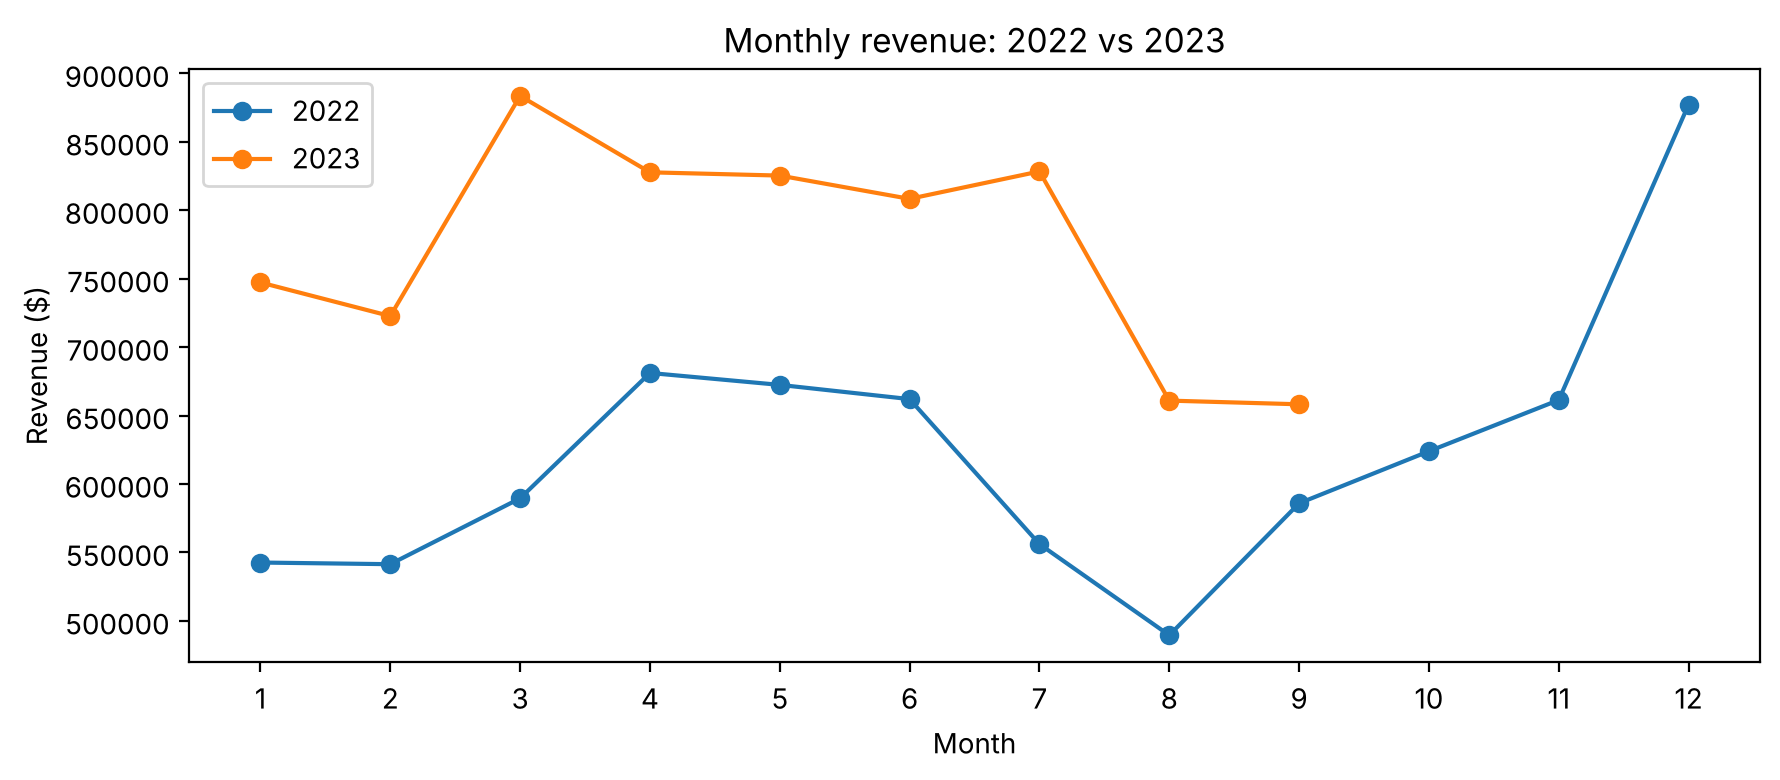

In [20]:
monthly["year"] = monthly["Month"].str[:4]
monthly["mon"] = monthly["Month"].str[5:].astype(int)

plt.figure(figsize=(9, 4))
for year, part in monthly.groupby("year"):
    plt.plot(part["mon"], part["revenue"], marker="o", label=year)
plt.title("Monthly revenue: 2022 vs 2023")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.savefig("monthly_revenue.png")
plt.show()

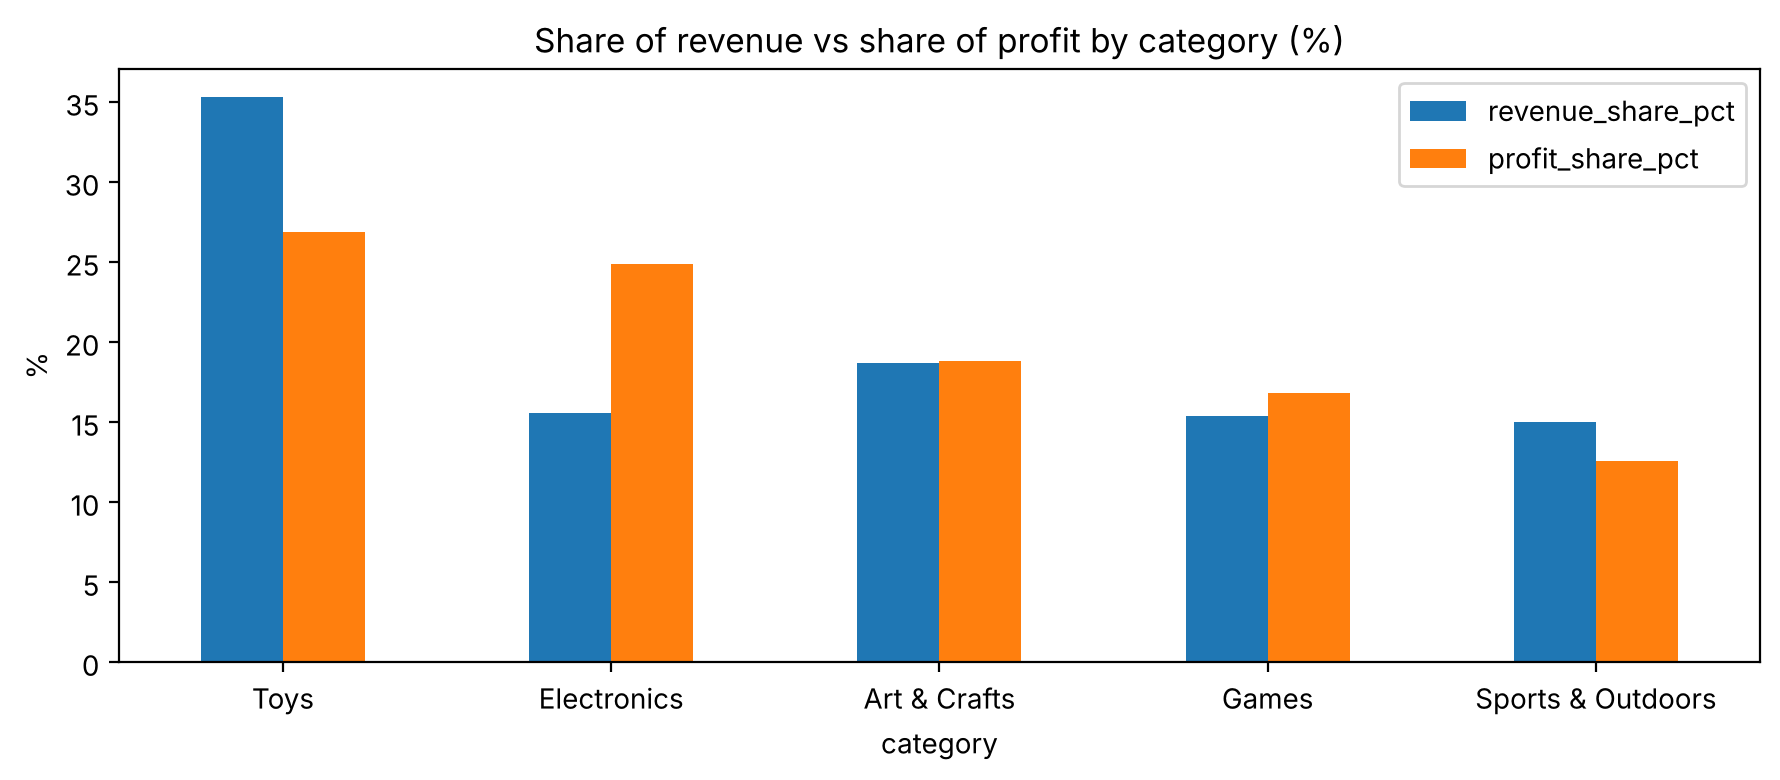

In [21]:
categories.set_index("category")[["revenue_share_pct", "profit_share_pct"]].plot(kind="bar", figsize=(9, 4))
plt.title("Share of revenue vs share of profit by category (%)")
plt.xticks(rotation=0)
plt.ylabel("%")
plt.tight_layout()
plt.savefig("category_share.png")
plt.show()

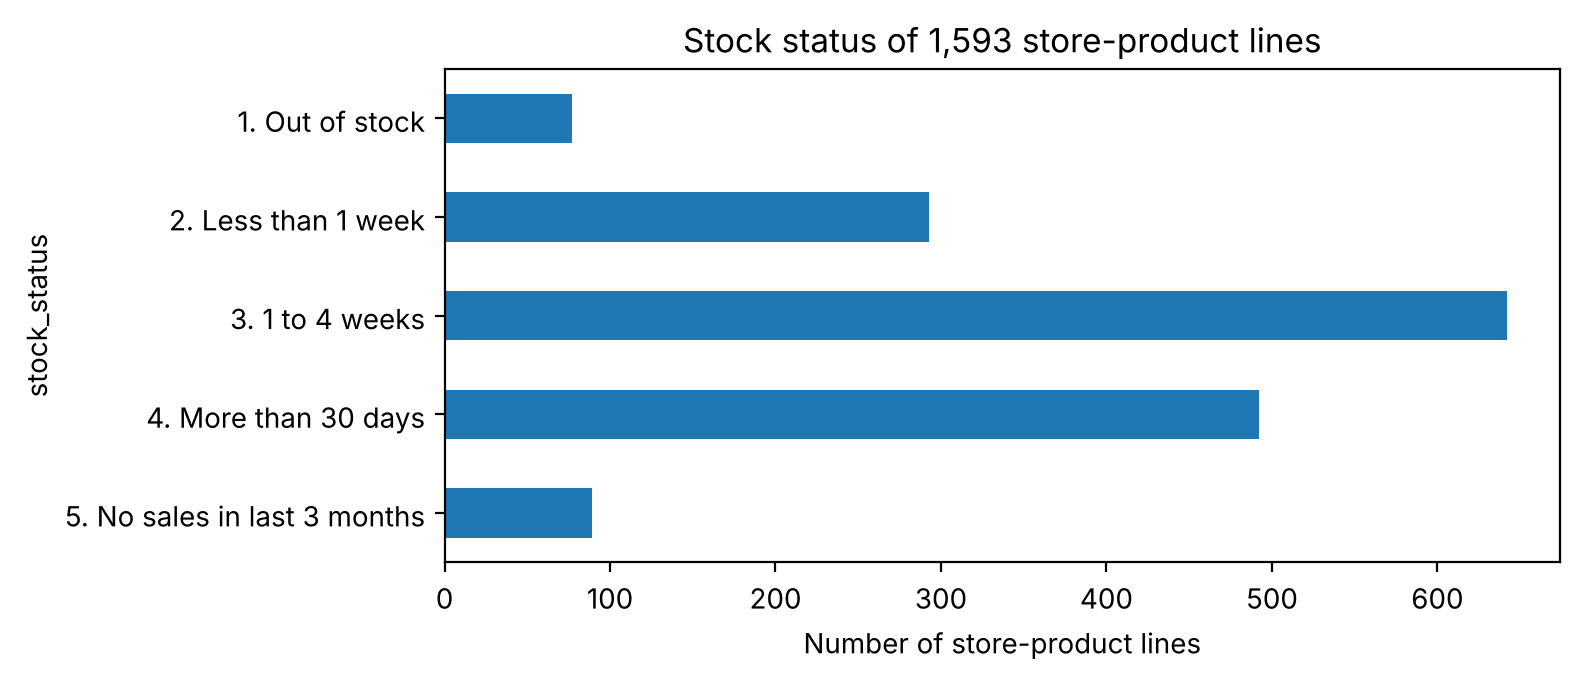

In [22]:
cover.set_index("stock_status")["store_product_lines"].sort_index(ascending=False).plot(kind="barh", figsize=(8, 3.5))
plt.title("Stock status of 1,593 store-product lines")
plt.xlabel("Number of store-product lines")
plt.tight_layout()
plt.savefig("stock_status.png")
plt.show()

## 4. Findings and recommendations

**Findings**
- Jan to Sep 2023 revenue is about 31% higher than Jan to Sep 2022, and every single month grew (query 2).
- Electronics is only about 16% of revenue but about 25% of profit, because its margin is 45% (Toys: 21%).
- **One product, Colorbuds, earns about 21% of total company profit.** Any supply problem with it would hit profit hard.
- The 3 airport stores earn about 63% more profit per store (about $126K vs $77K) than downtown, commercial or residential stores.
- About $300K (at cost) is tied up in stock. 293 store-product lines have less than a week of stock left, and 77 are already at zero.
- Stock-outs of items that were selling cost about $957 of revenue per day (about $29K per month).

**Recommendations**
1. Restock the out-of-stock items first, starting with the ones in query 11. They lose sales every day.
2. Set a reorder alert when days of cover falls below 7 days.
3. Protect Colorbuds supply (a second supplier or safety stock), and push other high-margin Electronics.
4. Consider airport locations for new stores.
5. Move stock out of items with no sales in 3 months (transfer to stores where they sell, or discount).

**Limitations**
- Inventory is a single snapshot, so days of cover assumes the last 3 months' sales rate continues.
- No data on rent, staff or other store costs, so "profit" here is gross profit (price minus product cost).